In [1]:
import os, json, time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

with open('../models/prep_config.json') as f:
    cfg = json.load(f)

SEED = cfg['SEED']
label2id = cfg['label2id']
id2label = {v: k for k, v in label2id.items()}
target_names = [id2label[i] for i in range(len(id2label))]
np.random.seed(SEED)
print('Config loaded:', cfg)

Config loaded: {'SEED': 42, 'MAX_LEN': 64, 'MIN_FREQ': 2, 'class_weight': {'negatif': 0.773647494999756, 'netral': 2.0379079928039063, 'positif': 0.8218801824212272}, 'label2id': {'negatif': 0, 'netral': 1, 'positif': 2}}


In [2]:
train_df = pd.read_csv('../data/processed/train.csv')
val_df = pd.read_csv('../data/processed/val.csv')

train_df['clean'] = train_df['clean'].fillna('')
val_df['clean'] = val_df['clean'].fillna('')

y_train = train_df['sentiment'].map(label2id).values
y_val = val_df['sentiment'].map(label2id).values

print(f'Train: {train_df.shape}, Val: {val_df.shape}')
print('Distribusi kelas val:', pd.Series(y_val).value_counts().sort_index().to_dict())

Train: (15859, 5), Val: (3398, 5)
Distribusi kelas val: {0: 1464, 1: 556, 2: 1378}


In [3]:
tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=20000,
    min_df=2,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(train_df['clean'])
X_val_tfidf = tfidf.transform(val_df['clean'])
print('X_train_tfidf shape:', X_train_tfidf.shape)
print('X_val_tfidf shape  :', X_val_tfidf.shape)

X_train_tfidf shape: (15859, 20000)
X_val_tfidf shape  : (3398, 20000)


In [4]:
t0 = time.time()
model_baseline = LinearSVC(
    C=1.0,
    class_weight='balanced',
    max_iter=2000,
    random_state=SEED,
    dual='auto'
)
model_baseline.fit(X_train_tfidf, y_train)
train_time = time.time() - t0

t1 = time.time()
y_val_pred = model_baseline.predict(X_val_tfidf)
inf_time = time.time() - t1
y_train_pred = model_baseline.predict(X_train_tfidf)

print(f'Training time  : {train_time:.4f}s')
print(f'Inference time : {inf_time:.4f}s (3.398 sampel val)')

Training time  : 2.1407s
Inference time : 0.0079s (3.398 sampel val)


In [5]:
metrics_baseline = {
    'model': 'Linear SVM (Baseline)',
    'train_accuracy': float(accuracy_score(y_train, y_train_pred)),
    'train_macro_f1': float(f1_score(y_train, y_train_pred, average='macro')),
    'val_accuracy': float(accuracy_score(y_val, y_val_pred)),
    'val_macro_precision': float(precision_score(y_val, y_val_pred, average='macro')),
    'val_macro_recall': float(recall_score(y_val, y_val_pred, average='macro')),
    'val_macro_f1': float(f1_score(y_val, y_val_pred, average='macro')),
    'val_weighted_f1': float(f1_score(y_val, y_val_pred, average='weighted')),
    'train_time_sec': float(train_time),
    'val_inf_time_sec': float(inf_time)
}

for k, v in metrics_baseline.items():
    print(f'{k:20s}: {v:.4f}' if isinstance(v, float) else f'{k:20s}: {v}')

print('\nClassification Report (Validation Set):')
print(classification_report(y_val, y_val_pred, target_names=target_names, digits=4))

model               : Linear SVM (Baseline)
train_accuracy      : 0.9489
train_macro_f1      : 0.9434
val_accuracy        : 0.6530
val_macro_precision : 0.5699
val_macro_recall    : 0.5703
val_macro_f1        : 0.5699
val_weighted_f1     : 0.6494
train_time_sec      : 2.1407
val_inf_time_sec    : 0.0079

Classification Report (Validation Set):
              precision    recall  f1-score   support

     negatif     0.7134    0.7261    0.7197      1464
      netral     0.2704    0.2446    0.2568       556
     positif     0.7260    0.7402    0.7330      1378

    accuracy                         0.6530      3398
   macro avg     0.5699    0.5703    0.5699      3398
weighted avg     0.6460    0.6530    0.6494      3398



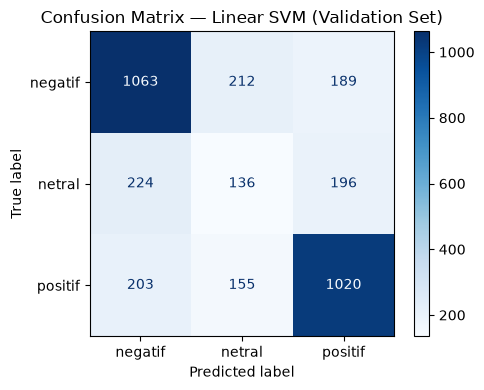

In [6]:
cm = confusion_matrix(y_val, y_val_pred)
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm, display_labels=target_names).plot(ax=ax, cmap='Blues', values_format='d')
ax.set_title('Confusion Matrix — Linear SVM (Validation Set)')
plt.tight_layout()
plt.show()

In [7]:
os.makedirs('../models', exist_ok=True)
joblib.dump(tfidf, '../models/tfidf_vectorizer.joblib')
joblib.dump(model_baseline, '../models/baseline_linear_svm.joblib')
with open('../models/val_metrics_baseline.json', 'w') as f:
    json.dump(metrics_baseline, f, indent=2)
print('Saved vectorizer, baseline model, and validation metrics.')

Saved vectorizer, baseline model, and validation metrics.
